Activity 1

In [ ]:
!pip install -q tensorflow_datasets importlib_resources
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
# Import TensorFlow Datasets (tfds) to download and load standard datasets
import tensorflow_datasets as tfds
from tensorflow.keras import layers, Model
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
SEED = 42

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Activity 2

In [ ]:
# Download (first run only) and load version 4.x.x of the Oxford-IIIT Pet dataset
# with_info=True also returns "info", an object holding metadata about the dataset
ds, info = tfds.load("oxford_iiit_pet:4.*.*", with_info=True)
# Print the number of images in the original training split
print("Train examples:", info.splits["train"].num_examples)
# Print the number of images in the original test split
print("Test examples :", info.splits["test"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.DXJKQ1_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.DXJKQ1_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Train examples: 3680
Test examples : 3669


Activity 3

In [ ]:
# Reload the dataset (it is already cached on disk, so nothing is downloaded this
# time)
ds, info = tfds.load("oxford_iiit_pet:4.*.*", with_info=True)
print("Original training examples:", info.splits["train"].num_examples)
print("Original testing examples :", info.splits["test"].num_examples)
# Use the complete original training split for training
train_data = ds["train"]
# Shuffle the original test split once so that validation and test sets are random
original_test = ds["test"].shuffle(
  # Buffer as large as the whole test split gives a complete, uniform shuffle
  buffer_size=info.splits["test"].num_examples,
  # Fixed seed makes the shuffle reproducible
  seed=SEED,
  # Keep one fixed order, otherwise validation and test images would mix between passes
  reshuffle_each_iteration=False
)
# Total number of images in the original test split
test_size = info.splits["test"].num_examples
# Half of them (integer division) will be used for validation
val_size = test_size // 2
# First half of the shuffled test split becomes the validation data
val_data = original_test.take(val_size)
# The remaining half becomes the final, independent test data
test_data = original_test.skip(val_size)

print("\nFinal dataset sizes:")
print("Training examples :", info.splits["train"].num_examples)
print("Validation examples:", val_size)
print("Testing examples :", test_size - val_size)

Original training examples: 3680
Original testing examples : 3669

Final dataset sizes:
Training examples : 3680
Validation examples: 1834
Testing examples : 1835


Activity 4

In [ ]:
# Define preprocess(): turns one raw dataset sample into an (image, mask) pair
# augment=True switches on random augmentation (used for the training set only)
def preprocess(sample, augment=False):
# Resize the RGB image to 128 x 128 pixels
  image = tf.image.resize(
    # The original image from the dataset sample
    sample["image"],
    # Target size (height, width)
    (128, 128)
  )
  # Resize the segmentation mask to the same 128 x 128 size
  mask = tf.image.resize(
    # The original mask from the dataset sample
    sample["segmentation_mask"],
    # Target size (height, width)
    (128, 128),
    # Nearest-neighbour keeps labels as whole numbers (no blended values)
    method="nearest"
  )
  # Convert pixels to float32 and scale from 0-255 to the range 0-1
  image = tf.cast(image, tf.float32) / 255.0
  # Convert labels to integers and shift them from 1,2,3 to 0,1,2
  mask = tf.cast(mask, tf.int32) - 1
  # Apply augmentation only when it was requested
  if augment:
  # With 50% probability (random number above 0.5) ...
    if tf.random.uniform(()) > 0.5:
      # ... flip the image horizontally
      image = tf.image.flip_left_right(image)
      # ... and flip the mask in the same way so it still matches the image
      mask = tf.image.flip_left_right(mask)
    # Randomly change the brightness by up to +/- 0.1 (image only, never the mask)
    image = tf.image.random_brightness(image, 0.1)
    # Clip pixel values back into the valid range 0-1
    image = tf.clip_by_value(image, 0.0, 1.0)

    # Return the processed image and mask
  return image, mask

Activity 5

In [ ]:
train_ds = (
  train_data
  # 1. Shuffle file paths/references BEFORE loading & preprocessing images
  .shuffle(1000)
  # 2. Unpack (image, mask) safely and apply preprocessing + augmentation
  .map(
    lambda *x: preprocess(*x, augment=True),
    num_parallel_calls=tf.data.AUTOTUNE
  )
  .batch(32)
  .prefetch(tf.data.AUTOTUNE)
)

# Validation pipeline (no augmentation, no shuffling)
val_ds = (
  val_data
  .map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
  )
  .batch(32)
  .prefetch(tf.data.AUTOTUNE)
)

# Test pipeline (no augmentation, no shuffling)
test_ds = (
  test_data
  .map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
  )
  .batch(32)
  .prefetch(tf.data.AUTOTUNE)
)


Activity 6

In [ ]:
def display(
  display_list,
  titles=("Image", "True mask", "Predicted mask")
  ):
  # Create a new figure 12 inches wide and 4 inches tall
  plt.figure(figsize=(12, 4))
  # Loop over the items to be shown (i = position, item = image or mask)
  for i, item in enumerate(display_list):
    # Select sub-plot number i+1 in a grid of 1 row and len(display_list) columns
    plt.subplot(1, len(display_list), i + 1)
    # Write the title above this sub-plot
    plt.title(titles[i])
    # Items after the first one are masks
    if i > 0:
      # Show the mask with the viridis colour map, fixing the colour range to labels 0-2
      plt.imshow(
        item,
        cmap="viridis",
        vmin=0,
        vmax=2
      )
    # The first item is the RGB image
    else:
      plt.imshow(item)
    # Hide the axis ticks and numbers
    plt.axis("off")
  plt.show()

  # Take one batch from the training pipeline
  for images, masks in train_ds.take(1):
  # Show the first three samples of the batch
    for i in range(3):
      # Plot sample i: [..., 0] removes the extra channel dimension of the mask
      display(
        [images[i], masks[i][..., 0]],
        titles=("Image", "True mask")
      )

Activity 7

In [ ]:
# conv_block(): two (Conv -> BatchNorm -> ReLU) layers, the basic unit of U-Net
def conv_block(x, filters):
  # 3x3 convolution with the given number of filters
  x = layers.Conv2D(
    filters,
    # Kernel size 3 (a 3x3 window)
    3,
    # "same" padding keeps the height and width unchanged
    padding="same",
    # he_normal is a weight initialization method used in NN and suits ReLU
    kernel_initializer="he_normal"
  )(x)
  # Normalise the activations to stabilise and speed up training
  x = layers.BatchNormalization()(x)
  x = layers.ReLU()(x)
  # Second 3x3 convolution with the same settings
  x = layers.Conv2D(
    filters,
    3,
    padding="same",
    kernel_initializer="he_normal"
  )(x)
  # Second batch normalisation
  x = layers.BatchNormalization()(x)
  # Second ReLU activation
  x = layers.ReLU()(x)
  # Return the feature maps
  return x

  # encoder_block(): extracts features and then halves the image size
def encoder_block(x, filters):
  # Features before pooling; they are kept as the skip connection for the decoder
  skip = conv_block(x, filters)
  # 2x2 max-pooling halves the height and width
  pooled = layers.MaxPooling2D(2)(skip)
  # Return the skip features and the pooled features
  return skip, pooled

  # decoder_block(): doubles the image size and merges it with the encoder features
def decoder_block(x, skip, filters):
  # Transposed convolution (stride 2) up-samples the feature maps to twice the size
  x = layers.Conv2DTranspose(
    filters,
    # 2x2 kernel
    2,
    # Stride 2 doubles the height and width
    strides=2,
    padding="same"
  )(x)
  # Join the up-sampled maps with the matching encoder (skip) features
  x = layers.Concatenate()([x, skip])
  # Refine the combined features with a convolution block
  x = conv_block(x, filters)
  # Return the decoded feature maps
  return x

  # build_unet(): assembles the complete network (default input is a 128x128 RGB image)
def build_unet(input_shape=(128, 128, 3)):
  # Input layer that receives the image
  inputs = layers.Input(input_shape)
  # Encoder
  # Level 1: 32 filters, 128x128 -> 64x64
  s1, p1 = encoder_block(inputs, 32)
  # Level 2: 64 filters, 64x64 -> 32x32
  s2, p2 = encoder_block(p1, 64)
  # Level 3: 128 filters, 32x32 -> 16x16
  s3, p3 = encoder_block(p2, 128)
  # Level 4: 256 filters, 16x16 -> 8x8
  s4, p4 = encoder_block(p3, 256)
  # Bottleneck

  # Deepest layer of the network with 512 filters
  b = conv_block(p4, 512)
  # Decoder
  # Up-sample to 16x16 and join with skip s4
  d1 = decoder_block(b, s4, 256)
  # Up-sample to 32x32 and join with skip s3
  d2 = decoder_block(d1, s3, 128)
  # Up-sample to 64x64 and join with skip s2
  d3 = decoder_block(d2, s2, 64)
  # Up-sample to 128x128 and join with skip s1
  d4 = decoder_block(d3, s1, 32)
  # Three output channels correspond to the three mask labels
  outputs = layers.Conv2D(
    # One channel per class (pet, background, border)
    3,
    # 1x1 convolution works on each pixel separately
    1,
    # Softmax turns the 3 values of every pixel into class probabilities
    activation="softmax"
  )(d4)
  # Create the Keras model from the input and output layers and name it "U-Net"
  return Model(inputs, outputs, name="U-Net")

model = build_unet()
model.summary()

Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,939 (29.65 MB)

 Trainable params: 7,766,051 (29.63 MB)

 Non-trainable params: 5,888 (23.00 KB)

Activity 8

In [ ]:
# Custom metric: inherits Keras' MeanIoU but accepts softmax probabilities as predictions
class MeanIoU(tf.keras.metrics.MeanIoU):
# update_state() is called after every batch to update the running IoU
  def update_state(self, y_true, y_pred, sample_weight=None):
    # Convert the 3 probabilities per pixel into the predicted class label (0, 1 or 2)
    y_pred = tf.argmax(y_pred, axis=-1)
    # Remove the extra channel dimension of the true mask
    y_true = tf.squeeze(y_true, axis=-1)
    # Pass the converted labels to the original MeanIoU implementation
    return super().update_state(
      y_true,
      y_pred,
      sample_weight
    )
model.compile(
  # Adam optimiser with a learning rate of 0.001
  optimizer=tf.keras.optimizers.Adam(1e-3),
  # Cross-entropy loss for integer labels and softmax probability outputs
  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
  metrics=[
  # Pixel accuracy: fraction of pixels classified correctly
  "accuracy",
  # Mean IoU over the 3 classes, reported under the name "mean_iou"
  MeanIoU(num_classes=3, name="mean_iou")
  ]
)

Activity 9

In [ ]:
callbacks = [
  # Save the model to disk whenever it improves
  tf.keras.callbacks.ModelCheckpoint(
    # File name of the saved model
    "best_unet.keras",
    # Watch the validation mean IoU
    monitor="val_mean_iou",
    # Higher mean IoU is better
    mode="max",
    save_best_only=True
  ),
  # Reduce the learning rate when progress stops
  tf.keras.callbacks.ReduceLROnPlateau(
    # Watch the validation loss
    monitor="val_loss",
    # Multiply the learning rate by 0.5 when triggered
    factor=0.5,
    # Wait for 3 epochs without improvement before reducing
    patience=3
  ),
  # Stop training when the model no longer improves
  tf.keras.callbacks.EarlyStopping(
    # Watch the validation loss
    monitor="val_loss",
    # Stop after 3 epochs without improvement
    patience=3,
    # Return to the weights of the best epoch when stopping
    restore_best_weights=True
  )
]

Activity 10

In [ ]:
history = model.fit(
train_ds,
validation_data=val_ds,
epochs=30,
callbacks=callbacks
)

Epoch 1/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 149s 556ms/step - accuracy: 0.7249 - loss: 0.6654 - mean_iou: 0.4517 - val_accuracy: 0.5405 - val_loss: 4.7779 - val_mean_iou: 0.2777 - learning_rate: 0.0010
Epoch 2/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 36s 297ms/step - accuracy: 0.8151 - loss: 0.4739 - mean_iou: 0.5779 - val_accuracy: 0.7608 - val_loss: 0.8990 - val_mean_iou: 0.5290 - learning_rate: 0.0010
Epoch 3/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 42s 349ms/step - accuracy: 0.8439 - loss: 0.4018 - mean_iou: 0.6250 - val_accuracy: 0.6725 - val_loss: 1.0962 - val_mean_iou: 0.4322 - learning_rate: 0.0010
Epoch 4/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 33s 271ms/step - accuracy: 0.8566 - loss: 0.3692 - mean_iou: 0.6465 - val_accuracy: 0.8491 - val_loss: 0.3973 - val_mean_iou: 0.6598 - learning_rate: 0.0010
Epoch 5/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 35s 276ms/step - accuracy: 0.8661 - loss: 0.3450 - mean_iou: 0.6633 - val_accuracy: 0.8606 - val_loss: 0.3829 - val_mean_iou: 0.6538 - learning_rate: 0.0010
Epoch 6/30
115

Activity 11

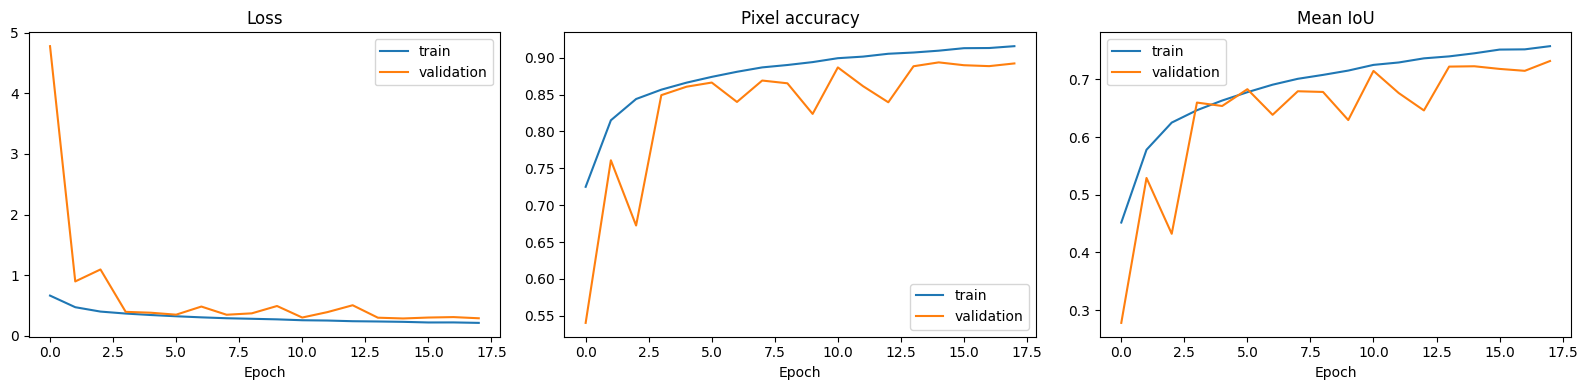

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (k, t) in zip(
ax,
  [
  ("loss", "Loss"),
  ("accuracy", "Pixel accuracy"),
  ("mean_iou", "Mean IoU")
  ]
):
  a.plot(history.history[k], label="train")
  a.plot(history.history["val_" + k], label="validation")
  a.set_title(t)
  a.set_xlabel("Epoch")
  a.legend()
plt.tight_layout()
plt.show()

Activity 12

In [ ]:
# Load the best model saved by ModelCheckpoint
model = tf.keras.models.load_model(
  # File that was written during training
  "best_unet.keras",
  # Tell Keras how to rebuild our custom MeanIoU metric
  custom_objects={"MeanIoU": MeanIoU}
)
print("\nFinal evaluation on independent test set:")
test_results = model.evaluate(
test_ds,
return_dict=True
)

for metric, value in test_results.items():
  print(f"{metric}: {value:.4f}")


Final evaluation on independent test set:
58/58 ━━━━━━━━━━━━━━━━━━━━ 26s 239ms/step - accuracy: 0.8940 - loss: 0.2815 - mean_iou: 0.7329
accuracy: 0.8940
loss: 0.2815
mean_iou: 0.7329


Activity 13

In [ ]:
# create_mask(): converts model probabilities to a class-label mask
def create_mask(pred):
  # Pick the most probable class for every pixel and return the first image's mask
  return tf.argmax(pred, axis=-1)[0]

# show_predictions(): plots image, true mask and predicted mask for "num" test images
def show_predictions(dataset, num=5):
  # Take one batch from the dataset
  for images, masks in dataset.take(1):
    # Predict the masks for the whole batch (verbose=0 hides the progress bar)
    preds = model.predict(images, verbose=0)
    # Loop over the first "num" images (or fewer if the batch is smaller)
    for i in range(min(num, len(images))):
    # Convert the 3 probabilities of every pixel to one class label (0, 1 or 2)
      pred_mask = tf.argmax(
      preds[i],
      axis=-1
      )
      # Show the image, the true mask and the predicted mask side by side
      display(
        [
        # Input image
        images[i],
        # Ground-truth mask (channel dimension removed)
        masks[i][..., 0],
        # Mask predicted by the U-Net

        pred_mask
        ],
        titles=(
        "Image",
        "True mask",
        "Predicted mask"

        )
      )
  # Show predictions for 5 images of the test set
  show_predictions(test_ds, num=5)